In [1]:
import pandas as pd

#https://www.kaggle.com/datasets/anselerol/job-postings-and-resumes-with-embeddings-faiss?resource=download
df = pd.read_csv('../data/raw/resumes.csv')
df['name'] = df['text'].apply(lambda x: x.split('Summary')[0].strip())

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2484 entries, 0 to 2483
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   id         2484 non-null   int64 
 1   text       2484 non-null   object
 2   name       2484 non-null   object
 3   embedding  2484 non-null   object
dtypes: int64(1), object(3)
memory usage: 77.8+ KB


In [3]:
df.head()

,id,text,name,embedding
0,1,HR ADMINISTRATOR/MARKETING ASSOCIATE\...,HR ADMINISTRATOR/MARKETING ASSOCIATE\n\nHR ADM...,"[-0.04447828233242035, 0.021229209378361702, 0..."
1,2,"HR SPECIALIST, US HR OPERATIONS ...","HR SPECIALIST, US HR OPERATIONS","[-0.05166391283273697, 0.01624675653874874, 0...."
2,3,HR DIRECTOR Summary Over 2...,HR DIRECTOR,"[-0.04784499853849411, 0.019322028383612633, -..."
3,4,HR SPECIALIST Summary Dedica...,HR SPECIALIST,"[-0.10490810126066208, 0.011350762099027634, 0..."
4,5,HR MANAGER Skill Highlights ...,HR MANAGER Skill Highlights ...,"[-0.06549879908561707, 0.04003952443599701, -0..."


In [4]:
df.iloc[0]['text']

"         HR ADMINISTRATOR/MARKETING ASSOCIATE\n\nHR ADMINISTRATOR       Summary     Dedicated Customer Service Manager with 15+ years of experience in Hospitality and Customer Service Management.   Respected builder and leader of customer-focused teams; strives to instill a shared, enthusiastic commitment to customer service.         Highlights         Focused on customer satisfaction  Team management  Marketing savvy  Conflict resolution techniques     Training and development  Skilled multi-tasker  Client relations specialist           Accomplishments      Missouri DOT Supervisor Training Certification  Certified by IHG in Customer Loyalty and Marketing by Segment   Hilton Worldwide General Manager Training Certification  Accomplished Trainer for cross server hospitality systems such as    Hilton OnQ  ,   Micros    Opera PMS   , Fidelio    OPERA    Reservation System (ORS) ,   Holidex    Completed courses and seminars in customer service, sales strategies, inventory control, loss pr

In [5]:
df.iloc[1]['text']

"         HR SPECIALIST, US HR OPERATIONS       Summary     Versatile  media professional with background in Communications, Marketing, Human Resources and Technology.\xa0        Experience     09/2015   to   Current     HR Specialist, US HR Operations    Company Name   －   City  ,   State       Managed communication regarding launch of Operations group, policy changes and system outages      Designed standard work and job aids to create comprehensive training program for new employees and contractors         Audited job postings for old, pending, on-hold and draft positions.           Audited union hourly, non-union hourly and salary background checks and drug screens             Conducted monthly new hire benefits briefing to new employees across all business units               Served as a link between HR Managers and vendors by handling questions and resolving system-related issues         Provide real-time process improvement feedback on key metrics and initiatives  Successfully r

In [6]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import ast  # Pour convertir les chaînes en listes si nécessaire

# Conversion des embeddings si stockés en chaîne
def convert_embedding(embedding_str):
    """Convertit une chaîne en liste numpy array"""
    if isinstance(embedding_str, str):
        return np.array(ast.literal_eval(embedding_str))
    elif isinstance(embedding_str, list):
        return np.array(embedding_str)
    else:
        return embedding_str

# Appliquer la conversion
df['embeddings_array'] = df['embedding'].apply(convert_embedding)

# Vérifier la dimension des embeddings
embedding_dim = len(df['embeddings_array'].iloc[0])
print(f"Dimension des embeddings : {embedding_dim}")

# Créer la matrice d'embeddings => c'est sur cette matrice qu'on va calculer les clusters
embeddings_matrix = np.vstack(df['embeddings_array'].values)
print(f"Shape de la matrice d'embeddings : {embeddings_matrix.shape}")

Dimension des embeddings : 384
Shape de la matrice d'embeddings : (2484, 384)


In [7]:
# ============================================
# FIX: Set all random seeds for reproducibility
# ============================================
import numpy as np
import random

# Set all random seeds
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)

# Sort dataframe by 'id' to ensure consistent ordering
df = df.sort_values('id').reset_index(drop=True)
print(f"✓ Random seeds set to {RANDOM_SEED}")
print(f"✓ DataFrame sorted by 'id' and reset: {len(df)} rows")

✓ Random seeds set to 42
✓ DataFrame sorted by 'id' and reset: 2484 rows


In [8]:
from sklearn.preprocessing import StandardScaler
# Normaliser les données
scaler = StandardScaler()
embeddings_matrix_normalized = scaler.fit_transform(embeddings_matrix)

In [9]:
pca = PCA(n_components=min(50, embedding_dim), random_state=RANDOM_SEED)  # Added random_state for reproducibility
embeddings_reduced = pca.fit_transform(embeddings_matrix_normalized)
print(f"Variance expliquée par les {pca.n_components_} composantes : {pca.explained_variance_ratio_.sum():.2%}")

Variance expliquée par les 50 composantes : 65.80%


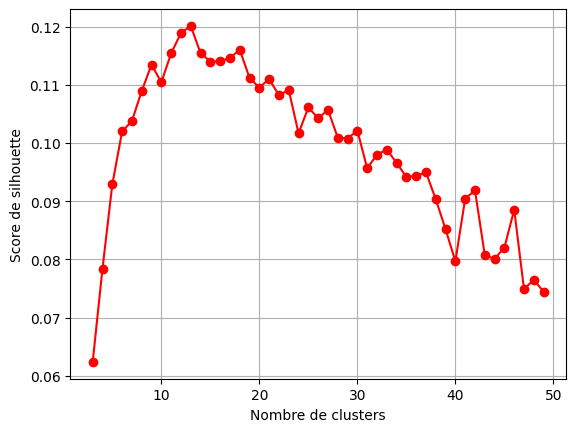

In [10]:
# 3. DÉTERMINATION DU NOMBRE OPTIMAL DE CLUSTERS (score de silhouette)
silhouette_scores = []
K_range = range(2, 50)  # Tester de 2 à 14 clusters

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(embeddings_reduced)
    #inertias.append(kmeans.inertia_)

    if k > 1:  # silhouette_score nécessite au moins 2 clusters
        score = silhouette_score(embeddings_reduced, kmeans.labels_)
        silhouette_scores.append(score)
    else:
        silhouette_scores.append(0)

plt.plot(K_range[1:], silhouette_scores[1:], 'ro-')
plt.xlabel('Nombre de clusters')
plt.ylabel('Score de silhouette')
plt.grid(True)
plt.show()

In [11]:
# 4. CLUSTERING AVEC K-MEANS (choisir k optimal)
optimal_k = 12  #Par exemple
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=20)
cluster_labels = kmeans.fit_predict(embeddings_reduced)

df['cluster'] = cluster_labels

# 5. ANALYSE DES CLUSTERS
# Statistiques par cluster
cluster_stats = df.groupby('cluster').agg({
    'id': 'count',
    #'source': lambda x: x.mode()[0] if len(x.mode()) > 0 else 'N/A',
    #'date': ['min', 'max']
}).round(2)

<Axes: xlabel='cluster'>

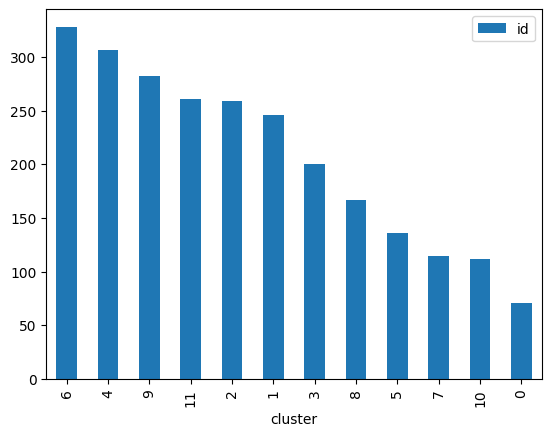

In [12]:
cluster_stats = cluster_stats.sort_values(by='id', ascending=False)  # si la colonne s'appelle 'title'
cluster_stats.plot(kind='bar')

In [13]:
import nltk
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np

# Télécharger les stop words français si nécessaire
nltk.download('stopwords')
english_stop_words = stopwords.words('english')

# Add custom stopwords for resume-specific noise
custom_stopwords = list(english_stop_words) + [
    'company', 'january', 'february', 'march', 'april', 'may', 'june',
    'july', 'august', 'september', 'october', 'november', 'december',
    'present', 'summary', 'experience', 'responsibilities', 'duties',
    'including', 'worked', 'years', 'responsible', 'various', 'multiple',
    'excellent', 'great', 'good', 'provided', 'ensured', 'created'
]

def extract_keywords_by_cluster(texts, labels, n_keywords=10):
    """Extrait les mots-clés TF-IDF par cluster"""
    unique_labels = np.unique(labels)
    keywords_by_cluster = {}

    for label in unique_labels:
        cluster_texts = [texts[i] for i in range(len(texts)) if labels[i] == label]

        if len(cluster_texts) < 2:
            keywords_by_cluster[label] = ["peu_de_documents"]
            continue

        # CRÉER UN NOUVEAU VECTORIZER POUR CHAQUE CLUSTER
        vectorizer = TfidfVectorizer(
            max_features=100,
            stop_words=custom_stopwords,
            ngram_range=(1, 3),  # Unigrams, bigrams and trigrams
            min_df=3,  # Mot doit apparaître dans au moins 3 docs du cluster
            max_df=0.5,  # Éliminer les mots apparaissant dans > 50% des docs
            token_pattern=r'(?u)\b[a-zA-Z][a-zA-Z]+\b'  # Au moins 2 lettres
        )

        try:
            tfidf_matrix = vectorizer.fit_transform(cluster_texts)
            feature_names = vectorizer.get_feature_names_out()

            if len(feature_names) == 0:
                keywords_by_cluster[label] = ["aucun_mot"]
                continue

            tfidf_scores = tfidf_matrix.mean(axis=0).A1
            top_indices = tfidf_scores.argsort()[-n_keywords:][::-1]
            top_keywords = [feature_names[i] for i in top_indices]
            keywords_by_cluster[label] = top_keywords

        except Exception as e:
            keywords_by_cluster[label] = [f"erreur: {str(e)[:30]}"]

    return keywords_by_cluster

# Utiliser la colonne 'text' ou 'chunk_text' pour l'extraction
texts = df['text'].fillna('').astype(str).tolist()
keywords_by_cluster = extract_keywords_by_cluster(texts, cluster_labels, n_keywords=4)

print("\nMots-clés par cluster :")
for cluster in sorted(keywords_by_cluster.keys()):
    keywords = keywords_by_cluster[cluster]
    print(f"Cluster {cluster}: {', '.join(keywords)}")

[nltk_data] Downloading package stopwords to
[nltk_data]     /home/khaledbouabdallah/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!



Mots-clés par cluster :
Cluster 0: wellness, customer service, member, equipment
Cluster 1: sql, database, engineering, servers
Cluster 2: sales, customer service, program, client
Cluster 3: press, event, strategy, client
Cluster 4: tax, payroll, credit, ledger
Cluster 5: customer service, sales, staffing, candidates
Cluster 6: construction, design, production, aviation
Cluster 7: executive chef, catering, cook, chef name
Cluster 8: children, service, grade, academic
Cluster 9: cash, merchandise, client, clients
Cluster 10: graphic, interior, marketing, art
Cluster 11: accounts, account, data, customer service


In [14]:
# For each cluster, randomly pick 5 sample resumes
np.random.seed(RANDOM_SEED)  # For reproducibility

print("\n" + "="*80)
print("SAMPLE RESUMES BY CLUSTER")
print("="*80)

for cluster_id in sorted(df['cluster'].unique()):
    cluster_df = df[df['cluster'] == cluster_id]
    n_samples = min(10, len(cluster_df))  # Take 3 samples or fewer if cluster is small

    samples = cluster_df.sample(n=n_samples, random_state=RANDOM_SEED)

    print(f"\n{'='*80}")
    print(f"CLUSTER {cluster_id} - Keywords: {', '.join(keywords_by_cluster[cluster_id])}")
    print(f"Total resumes: {len(cluster_df)}")
    print(f"{'='*80}\n")

    for idx, (_, row) in enumerate(samples.iterrows(), 1):
        # Extract first 400 characters for preview
        text_preview = row['text'][:400].replace('\n', ' ')
        print(f"Sample {idx}:")
        print(f"  Name: {row['name'][:50]}")
        print(f"  Preview: {text_preview}...")
        print()


SAMPLE RESUMES BY CLUSTER

CLUSTER 0 - Keywords: wellness, customer service, member, equipment
Total resumes: 71

Sample 1:
  Name: FITNESS TRAINER           Professional
  Preview:          FITNESS TRAINER           Professional Summary     Articulate Certified Personal Trainer driven to succeed. Strategic planning and client relationship management expert.  Looking to advance my career here at Planet Fitness and take my member oriented approach to a reach a much larger scale of members.       Core Qualifications          Very broad background in Fitness Industry.  Graduated...

Sample 2:
  Name: ASSISTANT FOOTBALL COACH
  Preview:          ASSISTANT FOOTBALL COACH       Summary    Enthusiastic, reliable recent graduate with academic background in business and marketing. Ability to establish priorities and meet challenges head-on. Strong leadership and management skills. Seeking a career in the business field.      Highlights        Exceptional interpersonal communication skills, Cus

/home/khaledbouabdallah/Projects/llm_grouping_loss_INRIA/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Computing t-SNE projection...
Computing UMAP projection...
Computing UMAP projection...


/home/khaledbouabdallah/Projects/llm_grouping_loss_INRIA/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/khaledbouabdallah/Projects/llm_grouping_loss_INRIA/.venv/lib/python3.13/site-packages/numba/np/ufunc/parallel.py:373: NumbaWarning: The TBB threading layer requires TBB version 2021 update 6 or later i.e., TBB_INTERFACE_VERSION >= 12060. Found TBB_INTERFACE_VERSION = 12050. The TBB threading layer is disabled.
  warnings.warn(problem)


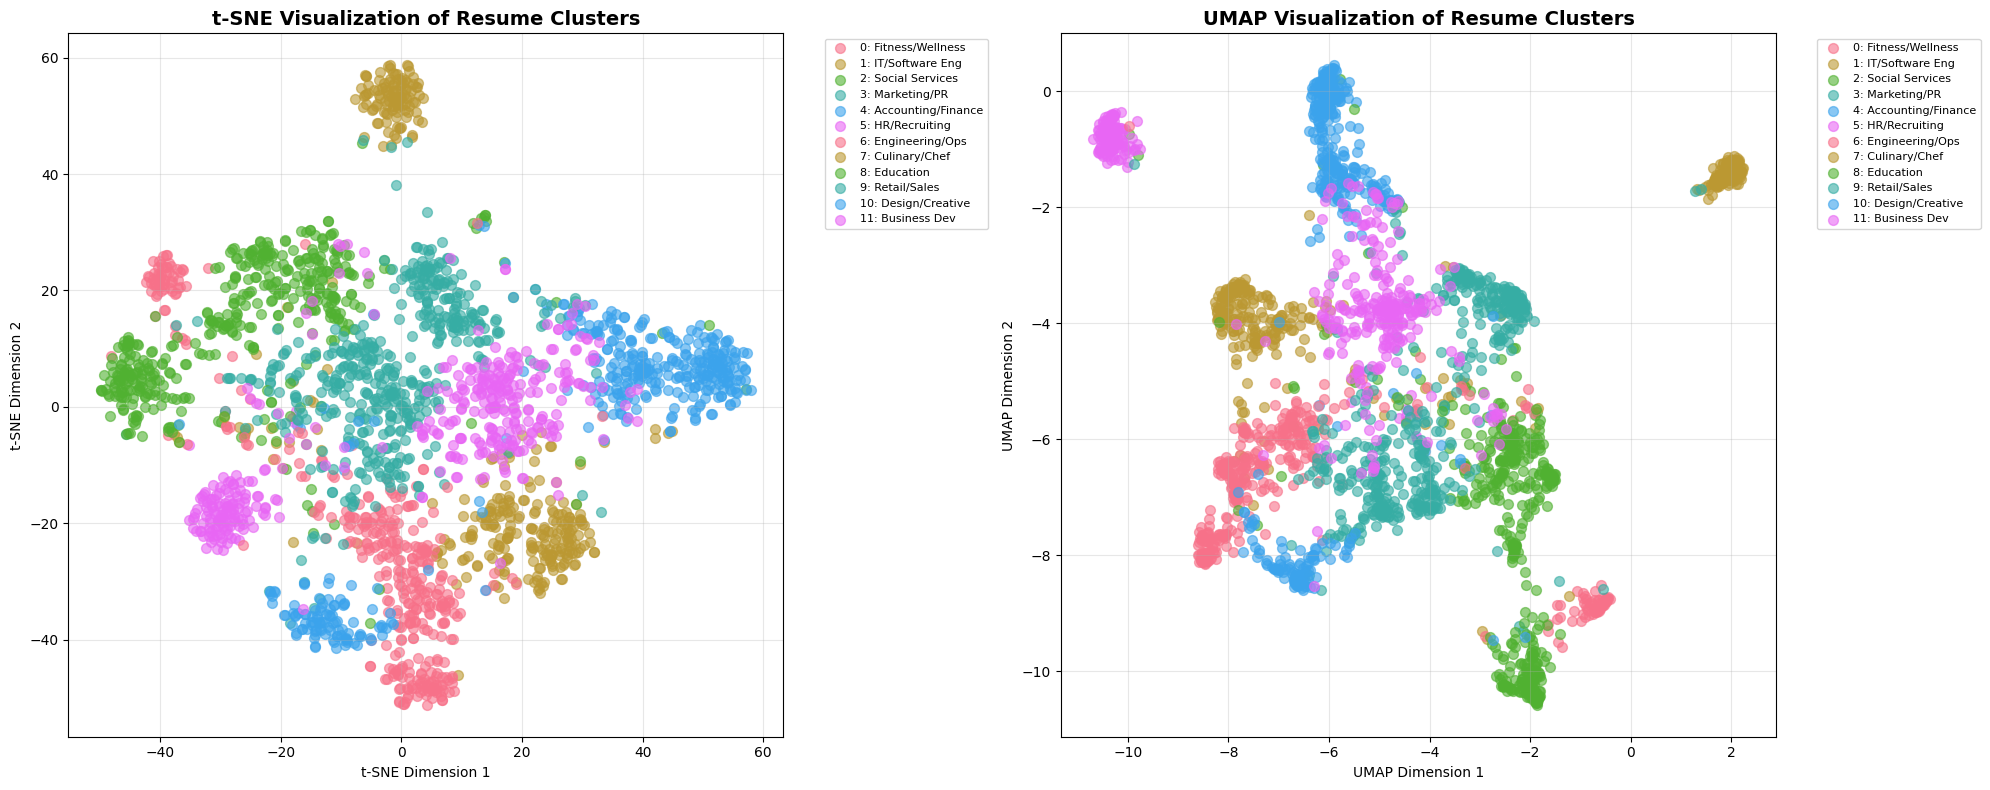

In [15]:
from sklearn.manifold import TSNE
import umap
import matplotlib.pyplot as plt
import seaborn as sns

# Set up the plot style
plt.style.use('default')
sns.set_palette("husl")

# Create figure with subplots
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# Define cluster names for better visualization
cluster_names = {
    0: "Fitness/Wellness",
    1: "IT/Software Eng",
    2: "Social Services",
    3: "Marketing/PR",
    4: "Accounting/Finance",
    5: "HR/Recruiting",
    6: "Engineering/Ops",
    7: "Culinary/Chef",
    8: "Education",
    9: "Retail/Sales",
    10: "Design/Creative",
    11: "Business Dev"
}

# 1. t-SNE visualization
print("Computing t-SNE projection...")
tsne = TSNE(n_components=2, random_state=RANDOM_SEED, perplexity=30, n_iter_without_progress=1000)
embeddings_tsne = tsne.fit_transform(embeddings_reduced)

# Plot t-SNE
for cluster_id in sorted(df['cluster'].unique()):
    mask = df['cluster'] == cluster_id
    axes[0].scatter(
        embeddings_tsne[mask, 0],
        embeddings_tsne[mask, 1],
        label=f"{cluster_id}: {cluster_names[cluster_id]}",
        alpha=0.6,
        s=50
    )

axes[0].set_title('t-SNE Visualization of Resume Clusters', fontsize=14, fontweight='bold')
axes[0].set_xlabel('t-SNE Dimension 1')
axes[0].set_ylabel('t-SNE Dimension 2')
axes[0].legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
axes[0].grid(True, alpha=0.3)

# 2. UMAP visualization
print("Computing UMAP projection...")
umap_model = umap.UMAP(n_components=2, random_state=RANDOM_SEED, n_neighbors=15, min_dist=0.1)
embeddings_umap = umap_model.fit_transform(embeddings_reduced)

# Plot UMAP
for cluster_id in sorted(df['cluster'].unique()):
    mask = df['cluster'] == cluster_id
    axes[1].scatter(
        embeddings_umap[mask, 0],
        embeddings_umap[mask, 1],
        label=f"{cluster_id}: {cluster_names[cluster_id]}",
        alpha=0.6,
        s=50
    )

axes[1].set_title('UMAP Visualization of Resume Clusters', fontsize=14, fontweight='bold')
axes[1].set_xlabel('UMAP Dimension 1')
axes[1].set_ylabel('UMAP Dimension 2')
axes[1].legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [16]:
# 3D Interactive visualization using plotly
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Compute 3D projections
print("Computing 3D t-SNE projection...")
tsne_3d = TSNE(n_components=3, random_state=RANDOM_SEED, perplexity=30, n_iter_without_progress=1000)
embeddings_tsne_3d = tsne_3d.fit_transform(embeddings_reduced)

print("Computing 3D UMAP projection...")
umap_3d = umap.UMAP(n_components=3, random_state=RANDOM_SEED, n_neighbors=15, min_dist=0.1)
embeddings_umap_3d = umap_3d.fit_transform(embeddings_reduced)

# Create subplots
fig = make_subplots(
    rows=1, cols=2,
    specs=[[{'type': 'scatter3d'}, {'type': 'scatter3d'}]],
    subplot_titles=('3D t-SNE Visualization', '3D UMAP Visualization')
)

# Color palette
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b',
          '#e377c2', '#7f7f7f', '#bcbd22', '#17becf', '#aec7e8', '#ffbb78']

# Add t-SNE traces
for cluster_id in sorted(df['cluster'].unique()):
    mask = df['cluster'] == cluster_id
    fig.add_trace(
        go.Scatter3d(
            x=embeddings_tsne_3d[mask, 0],
            y=embeddings_tsne_3d[mask, 1],
            z=embeddings_tsne_3d[mask, 2],
            mode='markers',
            name=f"{cluster_id}: {cluster_names[cluster_id]}",
            marker=dict(size=4, color=colors[cluster_id], opacity=0.7),
            text=[cluster_names[cluster_id]] * mask.sum(),
            hovertemplate='<b>%{text}</b><br>X: %{x:.2f}<br>Y: %{y:.2f}<br>Z: %{z:.2f}<extra></extra>'
        ),
        row=1, col=1
    )

# Add UMAP traces
for cluster_id in sorted(df['cluster'].unique()):
    mask = df['cluster'] == cluster_id
    fig.add_trace(
        go.Scatter3d(
            x=embeddings_umap_3d[mask, 0],
            y=embeddings_umap_3d[mask, 1],
            z=embeddings_umap_3d[mask, 2],
            mode='markers',
            name=f"{cluster_id}: {cluster_names[cluster_id]}",
            marker=dict(size=4, color=colors[cluster_id], opacity=0.7),
            text=[cluster_names[cluster_id]] * mask.sum(),
            hovertemplate='<b>%{text}</b><br>X: %{x:.2f}<br>Y: %{y:.2f}<br>Z: %{z:.2f}<extra></extra>',
            showlegend=False  # Avoid duplicate legends
        ),
        row=1, col=2
    )

# Update layout
fig.update_layout(
    title_text="3D Interactive Cluster Visualizations",
    height=700,
    showlegend=True,
    legend=dict(
        yanchor="top",
        y=0.99,
        xanchor="left",
        x=0.01,
        font=dict(size=9)
    )
)

fig.show()

Computing 3D t-SNE projection...
Computing 3D UMAP projection...
Computing 3D UMAP projection...


/home/khaledbouabdallah/Projects/llm_grouping_loss_INRIA/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [19]:
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

In [ ]:
cluster_names = {
    0: "Fitness/Wellness",
    1: "IT/Software Eng",
    2: "Social Services",
    3: "Marketing/PR",
    4: "Accounting/Finance",
    5: "HR/Recruiting",
    6: "Engineering/Ops",
    7: "Culinary/Chef",
    8: "Education",
    9: "Retail/Sales",
    10: "Design/Creative",
    11: "Business Dev"
}

templates = [
    "What skills does a {job_title} need?",
    "What is the average salary for a {job_title}?",
    "What education is required for a {job_title}?",
    "What are the main responsibilities of a {job_title}?",
    "What companies hire {job_title}s?"
]

def get_answer_with_confidence(question):
    inputs = tokenizer(question, return_tensors="pt").to(model.device)

    outputs = model.generate(
        **inputs,
        max_new_tokens=100,
        output_scores=True,
        return_dict_in_generate=True,
        do_sample=False  # greedy for consistency
    )

    # Extract token probabilities
    probs = []
    for score in outputs.scores:
        prob = torch.softmax(score, dim=-1).max().item()
        probs.append(prob)

    # Average token-level confidence
    avg_confidence = sum(probs) / len(probs)

    # Decode answer
    answer = tokenizer.decode(outputs.sequences[0][inputs.input_ids.shape[1]:])

    return answer, avg_confidence

In [ ]:

model_name = "mistralai/Mistral-7B-Instruct-v0.2"

# Create quantization config
quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",  # Normal Float 4 (recommended)
    bnb_4bit_compute_dtype=torch.bfloat16,  # Compute in bf16 for speed
    bnb_4bit_use_double_quant=True,  # Extra memory savings
)

# Load model
model = AutoModelForCausalLM.from_pretrained(
    model_name,
    quantization_config=quantization_config,
    device_map="auto",
)

tokenizer = AutoTokenizer.from_pretrained(model_name)


Fetching 3 files:   0%|          | 0/3 [35:56<?, ?it/s]
